# Shuffle, 10-fold Softmax và hard voting
Một vòng 10-fold tạo 10 mô hình. Mỗi lượt: 9 fold train, 1 fold held-out. Test MNIST chính thức giữ riêng. Hard voting dùng nhãn, không có bước fit tiếp sau khi ghép.

In [1]:
# Tích hợp và chạy thí nghiệm.
from pathlib import Path
import os, sys, json

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
from IPython.display import display, Image

RUN_TRAINING = False
if RUN_TRAINING or not (ROOT / "result/softmax_10fold/summary.csv").exists():
    from mnist_project.cross_validation import run

    ensemble = run()
R = ROOT / "result/softmax_10fold"


## Cấu hình cố định
Shuffle phân tầng seed 42; seed mô hình 42..51. LR=0,15, tối đa 100 epoch; Early Stopping theo validation loss, patience=10, min_delta=1e-4, khôi phục trọng số tốt nhất. Tách 10% từ 9 fold train làm validation nội bộ; held-out không tham gia chọn epoch.

In [2]:
print((R / "config.json").read_text())


{
  "n_splits": 10,
  "n_repeats": 1,
  "n_models": 10,
  "shuffle": true,
  "stratified": true,
  "split_seed": 42,
  "model_seeds": [
    42,
    43,
    44,
    45,
    46,
    47,
    48,
    49,
    50,
    51
  ],
  "epochs": 100,
  "learning_rate": 0.15,
  "batch_size": 256,
  "weight_decay": 0.0001,
  "n_development": 60000,
  "n_official_test": 10000,
  "early_stopping": true,
  "patience": 10,
  "min_delta": 0.0001,
  "restore_best_weights": true,
  "inner_validation_fraction": 0.1,
  "inner_validation_method": "sklearn.train_test_split(stratify=y)",
  "hyperparameter_selection": "Early stopping on inner validation only; heldout and official test excluded",
  "tie_break": "smallest class label",
  "python": "3.13.5",
  "numpy": "2.5.4",
  "sha256": "731c5ac602752760c8e48fbffcf8c3b850d9dc2a2aedcf2cc48468fc17b673d1"
}


## Điểm từng fold
Mỗi model chỉ đánh giá held-out trên fold chưa học. OOF gộp các dự đoán này; không bỏ phiếu cả 10 model trên dữ liệu training để báo cáo điểm CV.

,model,split,n,accuracy,precision_macro,recall_macro,f1_macro,fold,fit_seconds,predict_seconds,epochs_run,best_epoch,best_val_loss
0,fold_01,train,48600,0.92891,0.92813,0.92801,0.92800,1,4.65848,0.10277,57,54,0.30358
1,fold_01,early_stop,5400,0.91907,0.91802,0.91797,0.91781,1,4.65848,0.00822,57,54,0.30358
2,fold_01,heldout,6000,0.92000,0.91888,0.91899,0.91874,1,4.65848,0.00933,57,54,0.30358
3,fold_02,train,48600,0.93056,0.92982,0.92961,0.92967,2,7.72828,0.08530,97,87,0.28367
4,fold_02,early_stop,5400,0.92056,0.91980,0.91945,0.91951,2,7.72828,0.00953,97,87,0.28367
5,fold_02,heldout,6000,0.91783,0.91681,0.91663,0.91661,2,7.72828,0.00946,97,87,0.28367
6,fold_03,train,48600,0.92897,0.92818,0.92801,0.92804,3,7.10386,0.08641,86,76,0.27117
7,fold_03,early_stop,5400,0.92315,0.92239,0.92211,0.92214,3,7.10386,0.00896,86,76,0.27117
8,fold_03,heldout,6000,0.92517,0.92463,0.92399,0.92419,3,7.10386,0.00914,86,76,0.27117
9,fold_04,train,48600,0.93185,0.93108,0.93099,0.93098,4,8.05939,0.09101,100,99,0.27753


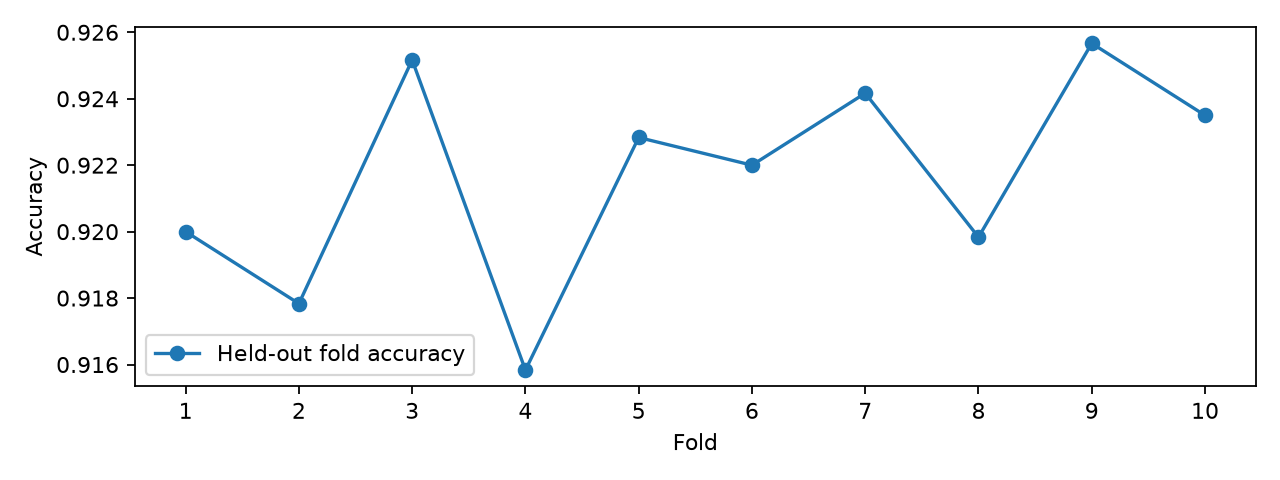

{
  "heldout_accuracy_mean": 0.9216833333333334,
  "heldout_accuracy_std": 0.0032350797116517415,
  "heldout_f1_macro_mean": 0.9206105196841543,
  "test_vote_ties": 29,
  "fit_seconds_total": 73.65243220000411
}


In [3]:
folds = pd.read_csv(R / "fold_metrics.csv")
display(folds.round(5))
display(Image(filename=str(ROOT / "result/figures/softmax_10fold/fold_accuracy.png")))
print((R / "aggregate.json").read_text())


## Tổ hợp hard voting trên test chính thức
Nếu hòa phiếu, lấy nhãn nhỏ nhất. Tất cả model được giữ lại, không chọn model tốt nhất bằng test.

In [4]:
display(pd.read_csv(R / "summary.csv").round(5))
display(pd.read_csv(R / "individual_test_metrics.csv").round(5))


,model,split,n,accuracy,precision_macro,recall_macro,f1_macro,predict_seconds
0,single_excluded_model,oof,60000,0.92168,0.92071,0.92062,0.92061,NaN
1,hard_voting_10_softmax,official_test,10000,0.92440,0.92339,0.92337,0.92328,0.05697


,model,split,n,accuracy,precision_macro,recall_macro,f1_macro
0,fold_01,official_test,10000,0.9231,0.92211,0.92210,0.92198
1,fold_02,official_test,10000,0.9239,0.92288,0.92283,0.92276
2,fold_03,official_test,10000,0.9236,0.92276,0.92252,0.92249
3,fold_04,official_test,10000,0.9252,0.92426,0.92418,0.92409
4,fold_05,official_test,10000,0.9253,0.92447,0.92421,0.92421
5,fold_06,official_test,10000,0.9232,0.92225,0.92210,0.92203
6,fold_07,official_test,10000,0.9228,0.92168,0.92183,0.92165
7,fold_08,official_test,10000,0.9242,0.92341,0.92312,0.92310
8,fold_09,official_test,10000,0.9256,0.92468,0.92464,0.92457
9,fold_10,official_test,10000,0.9247,0.92383,0.92362,0.92361


## Nạp tổ hợp và dự đoán
Chỉ nạp pickle do dự án tạo. Có 10 file model riêng và `hard_voting.pkl` chứa cả tổ hợp.

In [5]:
import pickle

with (R / "hard_voting.pkl").open("rb") as f:
    ensemble = pickle.load(f)
print("Số mô hình:", len(ensemble.models))
# Nhận X mới có shape (n,784), pixel [0,1]: ensemble.predict(X)


Metrics unit test: OK
Số mô hình: 10


## Diễn giải
Các train fold chồng lấn nên độ lệch chuẩn giữa fold không phải khoảng tin cậy của 10 thử nghiệm độc lập. So sánh với Softmax đơn cũ chỉ mang tính mô tả vì khác cấu hình/ngân sách dữ liệu. Tập test này đã từng được quan sát ở các phiên bản trước; kết quả là thực nghiệm phát triển, không phải một đánh giá cuối hoàn toàn mới.